# Buổi F2: DBSCAN và gom nhóm phân cấp, khi nhóm không tròn

**Hiện trường.** Chị Hạnh có bản đồ các điểm giao hàng. Có hai khu dân cư kéo dài theo hai con đường cong, lác đác vài điểm lẻ xa lộ. K-Means (F1) cắt thẳng ngang giữa, gộp lộn hai khu. Chị cần cách gom **theo mật độ**: chỗ nào đông đúc nối liền nhau thì là một nhóm, điểm lẻ loi thì để riêng.

Buổi này dạy hai cách khác K-Means:
- **DBSCAN**: nhóm là vùng điểm **dày đặc** nối liền nhau; điểm lẻ được gán nhãn `-1` (nhiễu). Không cần chọn trước số nhóm.
- **Gom nhóm phân cấp** (*hierarchical clustering*): bắt đầu mỗi điểm một nhóm, **gộp dần hai nhóm gần nhất**, vẽ thành cây (dendrogram), cắt cây ở độ cao nào thì ra từng ấy nhóm.

**Ẩn dụ:** DBSCAN giống nhìn bản đồ ánh sáng ban đêm: chỗ đèn sáng liền nhau là thành phố, đèn lẻ giữa đồng là nhà đơn độc. Gom phân cấp giống vẽ cây gia phả: hai anh em gộp thành một nhà, các nhà gộp thành họ.

**Mindset của người làm dữ liệu:** không có thuật toán gom nhóm tốt nhất; mỗi cái mang một **giả định về hình dạng nhóm**. Chọn thuật toán là chọn giả định.

**Lưu ý:** dữ liệu dựng có chủ đích bằng `make_moons` và `make_blobs`; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: K-Means cắt sai, DBSCAN đi theo đường cong |
| Chặng 1 | DBSCAN bằng tay: điểm lõi, điểm biên, nhiễu |
| Chặng 2 | Chọn eps: đường khoảng cách k-láng giềng |
| Chặng 3 | Gom phân cấp: cây và bốn cách đo khoảng cách nhóm |
| Chặng 4 | Bẫy: mật độ không đều giữa các nhóm |
| Chặng 5 | Nhiễu cũng là thông tin |

## Chặng 0: Thấy ngay, K-Means cắt sai

**Câu hỏi:** hai hình trăng lồng nhau, thuật toán nào gom đúng?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

K-Means ARI: 0.245 | DBSCAN ARI: 0.996
DBSCAN groups found: 2 | noise points: 1


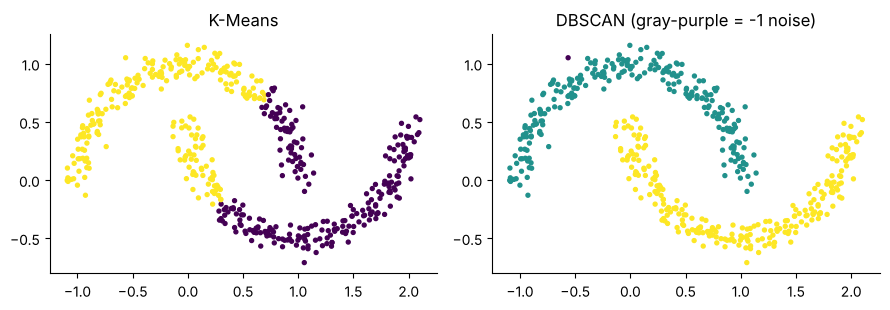

In [2]:
from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score
X, truth = make_moons(500, noise=0.07, random_state=0)
lab_km = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
lab_db = DBSCAN(eps=0.15, min_samples=5).fit_predict(X)
print("K-Means ARI:", round(adjusted_rand_score(truth, lab_km), 3), "| DBSCAN ARI:", round(adjusted_rand_score(truth, lab_db), 3))
print("DBSCAN groups found:", len(set(lab_db) - {-1}), "| noise points:", int((lab_db == -1).sum()))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].scatter(*X.T, c=lab_km, s=8); ax[0].set_title("K-Means")
ax[1].scatter(*X.T, c=lab_db, s=8); ax[1].set_title("DBSCAN (gray-purple = -1 noise)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `make_moons(500, noise=0.07)`: hai hình trăng lưỡi liềm lồng nhau, dữ liệu dựng có chủ đích. `truth` là nhãn thật chỉ để chấm.
- `DBSCAN(eps=0.15, min_samples=5)`: `eps`: bán kính "hàng xóm" (khoảng cách tối đa để hai điểm coi là gần nhau). `min_samples`: số hàng xóm tối thiểu để một điểm là "đông đúc".
- `.fit_predict(X)`: trả về nhãn nhóm cho từng điểm; nhãn `-1` nghĩa là nhiễu, không thuộc nhóm nào.
- `set(lab_db) - {-1}`: đếm số nhóm thật sự, bỏ nhãn nhiễu.

**Cách đọc.**
- **Con số:** K-Means khớp hình thật ở mức **0,245**, DBSCAN **0,996**. DBSCAN tìm ra **2** nhóm và để **1** điểm là nhiễu.
- **Bức tranh:** K-Means cắt đường thẳng giữa, DBSCAN đi theo đường cong vì nó chỉ hỏi "điểm này có hàng xóm sát bên không".
- **Câu hỏi tiếp:** "hàng xóm sát bên" định nghĩa chính xác thế nào? Ta tự đếm.

**Mang về chặng 1:** DBSCAN gom theo mật độ nên đi theo hình dạng bất kỳ, không cần chọn trước số nhóm.

## Chặng 1: DBSCAN bằng tay, điểm lõi, điểm biên, nhiễu

**Câu hỏi:** máy phân loại từng điểm thế nào?

In [3]:
from sklearn.neighbors import NearestNeighbors
eps, min_samples = 0.15, 5
nn = NearestNeighbors(radius=eps).fit(X)
neighbor_count = np.array([len(ix) for ix in nn.radius_neighbors(X, return_distance=False)])
is_core = neighbor_count >= min_samples
db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
is_noise = db.labels_ == -1
kinds = pd.Series(np.where(is_core, "core", np.where(is_noise, "noise", "border")))
print(kinds.value_counts().to_string())
print("my core points equal sklearn core points:", bool(np.array_equal(np.sort(db.core_sample_indices_), np.where(is_core)[0])))

core      495
border      4
noise       1
my core points equal sklearn core points: True


**Giải thích từng dòng**

- `NearestNeighbors(radius=eps)`: công cụ tìm các điểm nằm trong bán kính `eps` quanh một điểm.
- `nn.radius_neighbors(X, return_distance=False)`: với mỗi điểm, danh sách các điểm hàng xóm (tính cả chính nó).
- `neighbor_count >= min_samples`: **điểm lõi**: có đủ hàng xóm. Các điểm lõi nối liền nhau thành một nhóm.
- `np.where(is_core, "core", np.where(is_noise, "noise", "border"))`: **điểm biên**: không đủ hàng xóm nhưng nằm sát một điểm lõi nên vẫn thuộc nhóm. **Nhiễu**: không lõi, không sát lõi nào.
- `db.core_sample_indices_`: sklearn cũng lưu sẵn danh sách điểm lõi; ta so với bản tự đếm.

**Cách đọc.**
- **Con số:** **495** điểm lõi, **4** điểm biên, **1** điểm nhiễu. Danh sách điểm lõi tự đếm trùng khớp với sklearn.
- **Bức tranh:** thuật toán chỉ có ba loại điểm. Nhóm = các điểm lõi nối liền nhau, cộng các điểm biên bám vào. Nhiễu là điểm không ai nhận.
- **Câu hỏi tiếp:** `eps` chọn thế nào? Chọn lệch thì sao?

**Mang về chặng 2:** hai núm vặn `eps` và `min_samples` quyết định thế nào là "đông đúc".

## Chặng 2: Chọn eps

**Câu hỏi:** `eps` quá nhỏ hay quá lớn thì hỏng ra sao?

      groups  noise share    ARI
eps                             
0.03       4        0.956  0.001
0.06      26        0.288  0.049
0.10       3        0.036  0.706
0.15       2        0.002  0.996
0.25       2        0.000  1.000
0.40       1        0.000  0.000
0.60       1        0.000  0.000


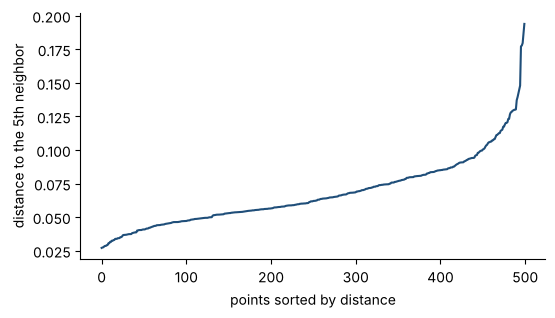

In [4]:
rows = []
for e in [0.03, 0.06, 0.10, 0.15, 0.25, 0.40, 0.60]:
    lab = DBSCAN(eps=e, min_samples=5).fit_predict(X)
    rows.append({"eps": e, "groups": len(set(lab) - {-1}), "noise share": round((lab == -1).mean(), 3), "ARI": round(adjusted_rand_score(truth, lab), 3)})
eps_table = pd.DataFrame(rows).set_index("eps")
print(eps_table.to_string())
kdist = np.sort(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(kdist, color=BLUE); ax.set_xlabel("points sorted by distance"); ax.set_ylabel("distance to the 5th neighbor")
plt.show()

**Giải thích từng dòng**

- `for e in [0.03, ..., 0.60]`: thử `eps` từ rất nhỏ đến rất lớn, giữ `min_samples = 5`.
- `"noise share"`: tỷ lệ điểm bị coi là nhiễu.
- `kneighbors(X)[0][:, -1]`: khoảng cách từ mỗi điểm đến hàng xóm thứ 5.
- `np.sort(...)`: xếp tăng dần. Chỗ đường **bắt đầu vọt lên** là gợi ý cho `eps`: từ đó trở đi là những điểm lẻ loi.

**Cách đọc.**
- **Con số:** ở `eps` nhỏ nhất (0.03) có **4** nhóm và **96%** là nhiễu; ở `eps` lớn nhất (0.6) còn **1** nhóm, ARI **0,000**. Tốt nhất là `eps` = **0.25** (ARI **1,000**).
- **Bức tranh:** `eps` quá nhỏ thì mọi thứ vỡ thành vụn và nhiễu; quá lớn thì hai nhóm dính làm một. Có một khoảng ở giữa chạy tốt.
- **Quy tắc đọc:** vẽ đường k-khoảng cách, chọn `eps` ở chỗ đường bắt đầu vọt, rồi thử xung quanh. Đừng tin một con số.
- **Câu hỏi tiếp:** nếu muốn nhìn cấu trúc ở nhiều mức (nhóm lớn, nhóm con) thì sao?

**Mang về chặng 3:** `eps` là núm vặn nhạy; luôn quét một dải.

## Chặng 3: Gom phân cấp, cây và cách đo khoảng cách nhóm

**Câu hỏi:** gộp dần hai nhóm gần nhất, nhưng "khoảng cách giữa hai nhóm" tính thế nào?

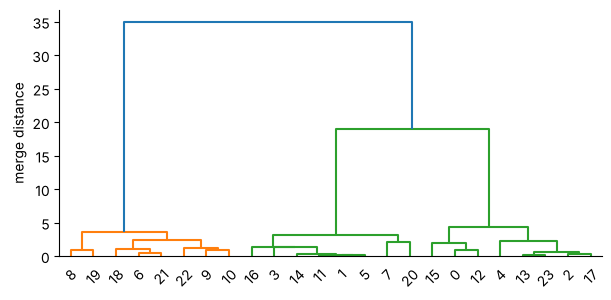

moons, agglomerative with 2 groups, ARI by linkage: {'ward': 0.445, 'complete': 0.523, 'average': 0.429, 'single': 1.0}


In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
small, small_true = make_blobs(n_samples=24, centers=3, cluster_std=0.9, random_state=3)
Z = linkage(small, method="ward")
fig, ax = plt.subplots(figsize=(7, 3.2))
dendrogram(Z, ax=ax, color_threshold=0.7 * Z[-1, 2])
ax.set_ylabel("merge distance")
plt.show()
cmp = {}
for method in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X)
    cmp[method] = round(adjusted_rand_score(truth, lab), 3)
print("moons, agglomerative with 2 groups, ARI by linkage:", cmp)

**Giải thích từng dòng**

- `make_blobs(n_samples=24, ...)`: chỉ 24 điểm để cây còn đọc được. Cây trăm điểm thì rối.
- `linkage(small, method="ward")`: ghi lại lịch sử gộp: mỗi hàng là một lần gộp hai nhóm, kèm khoảng cách lúc gộp. `ward` gộp sao cho nhóm mới tăng độ phân tán ít nhất.
- `dendrogram(Z, ...)`: vẽ cây. Chiều cao một nhánh nối là khoảng cách lúc gộp; cắt ngang cây ở độ cao nào thì ra từng ấy nhóm.
- `AgglomerativeClustering(n_clusters=2, linkage=method)`: bốn cách đo khoảng cách giữa hai nhóm: `ward` (tăng phân tán ít nhất), `complete` (hai điểm xa nhất), `average` (trung bình mọi cặp), `single` (hai điểm gần nhất).

**Cách đọc.**
- **Con số:** trên hai hình trăng, ARI theo cách đo: **{'ward': 0.445, 'complete': 0.523, 'average': 0.429, 'single': 1.0}**.
- **Bức tranh:** cách `single` (nối qua điểm gần nhất) lần theo được đường cong giống DBSCAN; `ward` và `complete` thiên về nhóm gọn nên cắt sai. Trên cây ở trên, độ cao nhánh nối nhảy vọt trước khi gộp hai nhóm cuối: chỗ nhảy đó là gợi ý số nhóm.
- **Quy tắc đọc:** `ward` là lựa chọn mặc định tốt cho nhóm gọn, tròn; `single` hợp nhóm dài, cong nhưng dễ bị "bắc cầu" bởi vài điểm nhiễu.
- **Câu hỏi tiếp:** DBSCAN dùng một `eps` cho cả bản đồ. Nếu chỗ đông chỗ thưa thì sao?

**Mang về chặng 4:** cách đo khoảng cách nhóm là giả định về hình dạng; cây giúp thấy nhiều mức.

## Chặng 4: Bẫy, mật độ không đều

**Câu hỏi:** một nhóm đặc, một nhóm thưa, một `eps` có phục vụ cả hai không?

In [6]:
dense, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.3, random_state=0)
sparse, _ = make_blobs(n_samples=300, centers=[[4, 0]], cluster_std=1.2, random_state=1)
Y = np.vstack([dense, sparse]); y_true = np.array([0] * 300 + [1] * 300)
rows = []
for e in [0.15, 0.3, 0.5, 0.8]:
    lab = DBSCAN(eps=e, min_samples=8).fit_predict(Y)
    rows.append({"eps": e, "groups": len(set(lab) - {-1}), "noise in dense": round((lab[:300] == -1).mean(), 3), "noise in sparse": round((lab[300:] == -1).mean(), 3), "ARI": round(adjusted_rand_score(y_true, lab), 3)})
dens = pd.DataFrame(rows).set_index("eps")
print(dens.to_string())
print("K-Means ARI:", round(adjusted_rand_score(y_true, KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Y)), 3))

      groups  noise in dense  noise in sparse    ARI
eps                                                 
0.15       1           0.093            1.000  0.822
0.30       6           0.000            0.437  0.695
0.50       2           0.000            0.120  0.894
0.80       2           0.000            0.047  0.955
K-Means ARI: 0.89


**Giải thích từng dòng**

- `cluster_std=0.3 / 1.2`: nhóm đầu rất đặc (độ lệch 0,3), nhóm sau rất thưa (1,2). Hai nhóm vẫn cùng 300 điểm.
- `DBSCAN(eps=e, min_samples=8)`: thử bốn bán kính.
- `lab[:300] == -1`: tỷ lệ nhiễu riêng trong từng nhóm thật: nhóm thưa dễ bị coi là nhiễu khi `eps` nhỏ.

**Cách đọc.**
- **Con số:** bảng trên cho thấy `eps` nhỏ (0.15) làm **100%** nhóm thưa thành nhiễu, còn `eps` lớn (0.8) cho ARI **0,955**. Tốt nhất là `eps` = **0.8** với ARI **0,955**. K-Means trên cặp này đạt **0,890**.
- **Bức tranh:** `eps` phải đặt theo nhóm **thưa** nhất mới giữ được nó; `eps` nhỏ làm nhóm thưa vụn hoặc thành nhiễu, và ở `eps` vừa phải vẫn còn vài điểm rìa nhóm thưa bị bỏ rơi. Với hai nhóm tách xa như thế này, `eps` đủ lớn cho kết quả tốt và chưa thấy hại gì ở nhóm đặc. Cái giá lộ ra khi các nhóm đặc nằm sát nhau: `eps` nới theo nhóm thưa sẽ dính chúng lại.
- **Quy tắc đọc:** không có `eps` cho tất cả; nếu quét một dải mà không tìm được điểm giữa, thử `HDBSCAN` (`sklearn.cluster.HDBSCAN`) hoặc K-Means/GMM (F3) khi nhóm gần tròn.

**Mang về chặng 5:** `eps` phải đặt theo nhóm thưa nhất; mật độ lệch nhiều thì cần công cụ khác.

## Chặng 5: Nhiễu cũng là thông tin

**Câu hỏi:** nhãn `-1` là rác hay là thứ đáng xem?

In [7]:
cust, _ = make_blobs(n_samples=500, centers=[[25, 8], [50, 15]], cluster_std=[3, 3.5], random_state=2)
odd = np.array([[70, 40], [18, 35], [62, 2], [30, 45]])
allc = np.vstack([cust, odd])
from sklearn.preprocessing import StandardScaler
Z2 = StandardScaler().fit_transform(allc)
lab2 = DBSCAN(eps=0.35, min_samples=8).fit_predict(Z2)
flag = pd.DataFrame(allc[lab2 == -1], columns=["age", "spend_million"]).round(1)
print("groups:", len(set(lab2) - {-1}), "| flagged as noise:", len(flag))
print("the 4 planted oddities flagged:", [bool(lab2[500 + i] == -1) for i in range(4)])
print(flag.head(8).to_string())

groups: 2 | flagged as noise: 11
the 4 planted oddities flagged: [True, True, True, True]
    age  spend_million
0  56.1            6.9
1  61.2           10.3
2  37.3           10.5
3  49.4           24.4
4  44.7            6.2
5  59.1           18.3
6  42.4            9.7
7  70.0           40.0


**Giải thích từng dòng**

- `odd = np.array([[70, 40], ...])`: cài vào 4 khách bất thường có chủ đích: chi rất nhiều, hoặc tuổi lệch hẳn khỏi hai nhóm chính.
- `StandardScaler().fit_transform(allc)`: chuẩn hóa vì DBSCAN cũng dùng khoảng cách (F1, chặng 3).
- `allc[lab2 == -1]`: lọc các khách bị gán nhãn nhiễu để xem.

**Cách đọc.**
- **Con số:** DBSCAN tìm **2** nhóm và gắn nhãn nhiễu cho **11** khách; bốn khách cài sẵn có bị bắt không: **True**.
- **Bức tranh:** ngoài hai nhóm chính, danh sách nhiễu là chỗ nên mở ra xem: khách chi tiêu bất thường, nhập sai dữ liệu, hay một nhóm nhỏ chưa được đặt tên. Buổi F6 đi sâu vào việc tìm điểm bất thường.
- **Lưu ý:** nhiễu của DBSCAN phụ thuộc `eps` và `min_samples`; đừng xóa khách chỉ vì có nhãn `-1`.

**Mang về:** chọn thuật toán theo hình dạng nhóm; nhãn nhiễu là danh sách cần kiểm, không phải danh sách cần xóa.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | DBSCAN gom theo mật độ, đi theo hình dạng bất kỳ, không cần chọn số nhóm. |
| 1 | Ba loại điểm: lõi, biên, nhiễu; nhóm = điểm lõi nối liền. |
| 2 | eps là núm nhạy: quá nhỏ vụn, quá lớn dính; quét một dải. |
| 3 | Gom phân cấp cho cây nhiều mức; cách đo khoảng cách nhóm là giả định hình dạng. |
| 4 | Mật độ giữa các nhóm khác nhau nhiều thì một eps không đủ. |
| 5 | Nhãn nhiễu là danh sách cần kiểm tra, không phải cần xóa. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Đèn sáng liền nhau là thành phố | gom theo mật độ | `DBSCAN` |
| Bán kính hàng xóm | bán kính lân cận | `eps` |
| Cần bao nhiêu hàng xóm thì tính là đông | số mẫu tối thiểu | `min_samples` |
| Nhà đơn độc giữa đồng | điểm nhiễu | nhãn `-1` |
| Cây gia phả | biểu đồ cây | `dendrogram` |
| Gộp hai nhà gần nhất | gom nhóm phân cấp | `AgglomerativeClustering` |
| Cách đo khoảng cách hai họ | kiểu liên kết | `linkage` |

**Thử thách tự làm**

1. Ở chặng 2, đổi `min_samples` từ 5 sang 15. Dải `eps` chạy tốt dịch chuyển thế nào?
2. Thêm vào `make_moons` một lớp nhiễu ngẫu nhiên 5%. Cách `single` của chặng 3 còn tốt không?
3. Thử `sklearn.cluster.HDBSCAN` trên dữ liệu chặng 4. Nó có xử lý được mật độ khác nhau không?
4. Dùng `dendrogram` cho 40 khách thật của một bộ dữ liệu bạn có và đề xuất số nhóm từ chỗ nhánh nhảy vọt.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích điểm lõi, điểm biên, nhiễu.
- [ ] Chọn eps bằng đường k-khoảng cách và quét một dải.
- [ ] Đọc cây gom phân cấp.
- [ ] Biết khi nào DBSCAN hợp, khi nào K-Means hợp.
- [ ] Coi nhãn nhiễu là danh sách cần kiểm tra.

## Phần thưởng (Tip pro): HDBSCAN: DBSCAN không cần chọn eps


`HDBSCAN` chạy DBSCAN ở mọi `eps` cùng lúc rồi giữ những nhóm bền vững nhất, nên chịu được mật độ khác nhau và không cần chọn `eps`. Từ sklearn 1.3 có sẵn ở `sklearn.cluster.HDBSCAN`.